downloading Olivetti faces from https://ndownloader.figshare.com/files/5976027 to /root/scikit_learn_data
Dataset: (400, 4096)
Training: (240, 4096)
Validation: (80, 4096)
Test: (80, 4096)

Q1(a)
 Depth  Min leaf  Train accuracy  Validation accuracy  Test accuracy  Leaves  Mean leaf size  Singleton fraction
   2.0         1        0.075000               0.0750         0.0750       3       80.000000             0.00000
   2.0         2        0.075000               0.0750         0.0750       3       80.000000             0.00000
   2.0         4        0.075000               0.0750         0.0750       3       80.000000             0.00000
   2.0         8        0.075000               0.0625         0.0500       3       80.000000             0.00000
   4.0         1        0.125000               0.0875         0.0875       5       48.000000             0.00000
   4.0         2        0.125000               0.0875         0.0875       5       48.000000             0.00000
   4.0       

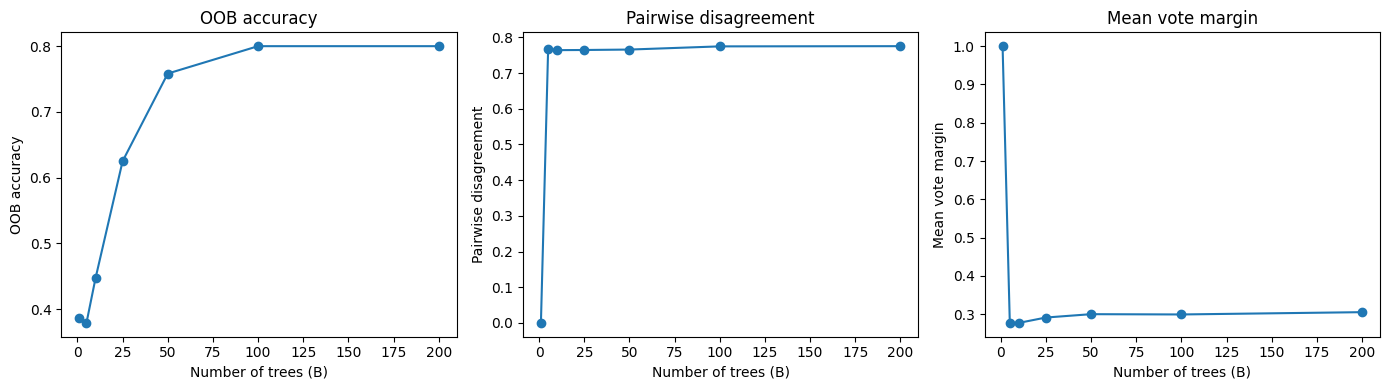

Selected final B: 200

Q1(d)
      Model  Clean accuracy  Masked accuracy  Clean confidence  Masked confidence
Single tree           0.500            0.375           1.00000           1.000000
    Bagging           0.825            0.550           0.38975           0.277062

Bagging corrects the tree
{'test_index': 2, 'true_identity': 1, 'tree_prediction': 11, 'bagging_prediction': 1, 'tree_confidence': 1.0, 'bagging_confidence': 0.485, 'bagging_vote_counts': [0, 97, 0, 21, 4, 0, 2, 0, 0, 0, 1, 2, 2, 0, 1, 3, 2, 4, 3, 6, 1, 3, 0, 0, 1, 1, 4, 2, 0, 1, 25, 3, 0, 5, 0, 0, 2, 1, 2, 1]}
{'test_index': 5, 'true_identity': 2, 'tree_prediction': 17, 'bagging_prediction': 2, 'tree_confidence': 1.0, 'bagging_confidence': 0.28, 'bagging_vote_counts': [5, 1, 56, 2, 7, 2, 1, 2, 1, 13, 2, 3, 11, 8, 8, 2, 3, 5, 2, 2, 1, 0, 6, 0, 5, 12, 5, 6, 3, 0, 1, 0, 0, 0, 1, 2, 2, 10, 0, 10]}

Both models are wrong
{'test_index': 0, 'true_identity': 0, 'tree_prediction': 26, 'bagging_prediction': 15, 'tree_confid

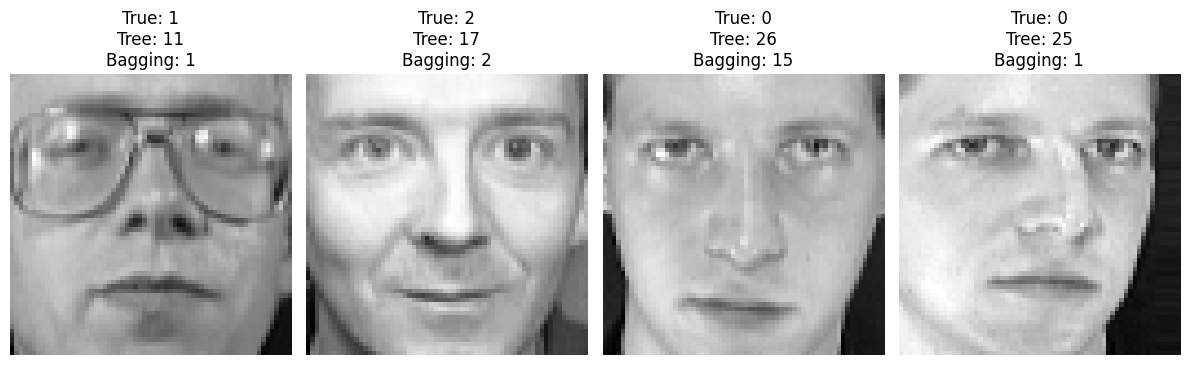

Q1 completed.


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from itertools import combinations
from sklearn.datasets import fetch_olivetti_faces
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

seed = int("".join(c for c in "p26cs0006" if c.isdigit()))
rng = np.random.default_rng(seed)

data = fetch_olivetti_faces()
X = data.data.astype(float)
y = data.target
classes = np.unique(y)

train_idx, val_idx, test_idx = [], [], []

for c in classes:
    idx = rng.permutation(np.flatnonzero(y == c))
    train_idx.extend(idx[:6])
    val_idx.extend(idx[6:8])
    test_idx.extend(idx[8:10])

train_idx = np.array(train_idx)
val_idx = np.array(val_idx)
test_idx = np.array(test_idx)

Xtr, ytr = X[train_idx], y[train_idx]
Xv, yv = X[val_idx], y[val_idx]
Xt, yt = X[test_idx], y[test_idx]

Xm = Xt.reshape(-1, 64, 64).copy()
Xm[:, 24:40, 24:40] = 0
Xm = Xm.reshape(-1, 4096)

print("Dataset:", X.shape)
print("Training:", Xtr.shape)
print("Validation:", Xv.shape)
print("Test:", Xt.shape)

results = []
best_acc = -1

for depth in [2, 4, 8, 16, None]:
    for leaf in [1, 2, 4, 8]:
        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=seed
        )
        model.fit(Xtr, ytr)

        train_acc = accuracy_score(ytr, model.predict(Xtr))
        val_acc = accuracy_score(yv, model.predict(Xv))
        test_acc = accuracy_score(yt, model.predict(Xt))

        leaves = model.tree_.children_left == -1
        sizes = model.tree_.n_node_samples[leaves]

        results.append([
            depth, leaf, train_acc, val_acc, test_acc,
            leaves.sum(), sizes.mean(), np.mean(sizes == 1)
        ])

        if val_acc > best_acc:
            best_acc = val_acc
            best_tree = model
            params = {
                "max_depth": depth,
                "min_samples_leaf": leaf
            }

print("\nQ1(a)")
print(pd.DataFrame(results, columns=[
    "Depth", "Min leaf", "Train accuracy", "Validation accuracy",
    "Test accuracy", "Leaves", "Mean leaf size", "Singleton fraction"
]).to_string(index=False))

print("Best parameters:", params)
print("Best validation accuracy:", best_acc)

B_values = [1, 5, 10, 25, 50, 100, 200]
n = len(Xtr)
class_map = {c: i for i, c in enumerate(classes)}
bag_rng = np.random.default_rng(seed + 1)

trees, samples, distinct = [], [], []

for _ in range(max(B_values)):
    idx = bag_rng.integers(0, n, size=n)
    tree = DecisionTreeClassifier(
        **params,
        random_state=int(bag_rng.integers(0, 2**31 - 1))
    )
    tree.fit(Xtr[idx], ytr[idx])
    trees.append(tree)
    samples.append(idx)
    distinct.append(len(np.unique(idx)))

expected_distinct = n * (1 - (1 - 1 / n) ** n)


def get_votes(models, data):
    votes = np.zeros((len(data), len(classes)), dtype=int)
    for tree in models:
        pred = tree.predict(data)
        for i, label in enumerate(pred):
            votes[i, class_map[label]] += 1
    return votes


def predict(models, data):
    return classes[get_votes(models, data).argmax(axis=1)]


bag_results = []
diagnostics = []

for B in B_values:
    ensemble = trees[:B]

    bag_results.append([
        B,
        accuracy_score(ytr, predict(ensemble, Xtr)),
        accuracy_score(yv, predict(ensemble, Xv)),
        accuracy_score(yt, predict(ensemble, Xt)),
        np.mean(distinct[:B]),
        expected_distinct
    ])

    oob_votes = np.zeros((n, len(classes)), dtype=int)

    for tree, sample in zip(ensemble, samples[:B]):
        oob_idx = np.setdiff1d(np.arange(n), np.unique(sample))
        if len(oob_idx):
            pred = tree.predict(Xtr[oob_idx])
            for i, label in zip(oob_idx, pred):
                oob_votes[i, class_map[label]] += 1

    covered = oob_votes.sum(axis=1) > 0
    oob_acc = np.nan

    if covered.any():
        oob_pred = classes[oob_votes[covered].argmax(axis=1)]
        oob_acc = accuracy_score(ytr[covered], oob_pred)

    val_predictions = np.array([
        tree.predict(Xv) for tree in ensemble
    ])

    pairs = [
        np.mean(val_predictions[i] != val_predictions[j])
        for i, j in combinations(range(B), 2)
    ]

    fractions = np.sort(get_votes(ensemble, Xv) / B, axis=1)
    margin = np.mean(fractions[:, -1] - fractions[:, -2])

    diagnostics.append([
        B, oob_acc, np.mean(pairs) if pairs else 0,
        margin, accuracy_score(yv, predict(ensemble, Xv))
    ])

bag_df = pd.DataFrame(bag_results, columns=[
    "B", "Train accuracy", "Validation accuracy", "Test accuracy",
    "Average distinct examples", "Expected distinct examples"
])

diag_df = pd.DataFrame(diagnostics, columns=[
    "B", "OOB accuracy", "Pairwise disagreement",
    "Mean vote margin", "Validation accuracy"
])

print("\nQ1(b)")
print(bag_df.to_string(index=False))

print("\nQ1(c)")
print(diag_df.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, column in zip(axes, [
    "OOB accuracy", "Pairwise disagreement", "Mean vote margin"
]):
    ax.plot(diag_df["B"], diag_df[column], marker="o")
    ax.set_xlabel("Number of trees (B)")
    ax.set_ylabel(column)
    ax.set_title(column)

plt.tight_layout()
plt.show()

best_row = bag_df.sort_values(
    ["Validation accuracy", "B"],
    ascending=[False, True]
).iloc[0]

final_B = int(best_row["B"])
final_trees = trees[:final_B]

print("Selected final B:", final_B)


def single_tree_result(model, data):
    pred = model.predict(data)
    confidence = model.predict_proba(data).max(axis=1)
    return pred, confidence


def bagging_result(models, data):
    v = get_votes(models, data)
    pred = classes[v.argmax(axis=1)]
    confidence = v.max(axis=1) / len(models)
    return pred, confidence, v


tree_clean, tree_clean_conf = single_tree_result(best_tree, Xt)
tree_masked, tree_masked_conf = single_tree_result(best_tree, Xm)

bag_clean, bag_clean_conf, bag_clean_votes = bagging_result(
    final_trees, Xt
)
bag_masked, bag_masked_conf, bag_masked_votes = bagging_result(
    final_trees, Xm
)

comparison = pd.DataFrame([
    [
        "Single tree",
        accuracy_score(yt, tree_clean),
        accuracy_score(yt, tree_masked),
        tree_clean_conf.mean(),
        tree_masked_conf.mean()
    ],
    [
        "Bagging",
        accuracy_score(yt, bag_clean),
        accuracy_score(yt, bag_masked),
        bag_clean_conf.mean(),
        bag_masked_conf.mean()
    ]
], columns=[
    "Model", "Clean accuracy", "Masked accuracy",
    "Clean confidence", "Masked confidence"
])

print("\nQ1(d)")
print(comparison.to_string(index=False))

corrected = np.flatnonzero(
    (tree_clean != yt) & (bag_clean == yt)
)
both_wrong = np.flatnonzero(
    (tree_clean != yt) & (bag_clean != yt)
)


def show_examples(indices, title):
    print("\n" + title)
    for i in indices[:2]:
        print({
            "test_index": int(i),
            "true_identity": int(yt[i]),
            "tree_prediction": int(tree_clean[i]),
            "bagging_prediction": int(bag_clean[i]),
            "tree_confidence": float(tree_clean_conf[i]),
            "bagging_confidence": float(bag_clean_conf[i]),
            "bagging_vote_counts": bag_clean_votes[i].tolist()
        })


show_examples(corrected, "Bagging corrects the tree")
show_examples(both_wrong, "Both models are wrong")

selected = list(corrected[:2]) + list(both_wrong[:2])

if selected:
    fig, axes = plt.subplots(
        1, len(selected), figsize=(3 * len(selected), 4)
    )
    axes = np.atleast_1d(axes)

    for ax, i in zip(axes, selected):
        ax.imshow(Xt[i].reshape(64, 64), cmap="gray")
        ax.set_title(
            f"True: {yt[i]}\nTree: {tree_clean[i]}\nBagging: {bag_clean[i]}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

print("Q1 completed.")
